# UTS Graf Sains Data: Neo4j dan Rekomendasi Data Retail

Nama / NIM: Muhammad Zikri Widiandra (240315554088). Dataset: RetailRocket (events.csv). Periode filter: P1 (training) 18-31 Mei 2015 dan P2 (testing) 16-30 Juni 2015.

In [1]:
import os
from dotenv import load_dotenv
from neo4j import GraphDatabase, RoutingControl

load_dotenv(r"C:\Users\lenovo\Downloads\Neo4j-716e22f7-Created-2026-10-19.txt")

URI = os.getenv("NEO4J_URI").replace("neo4j+s://", "neo4j+ssc://")
USER = os.getenv("NEO4J_USERNAME")
PASSWORD = os.getenv("NEO4J_PASSWORD")
DB = os.getenv("NEO4J_DATABASE")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()

In [ ]:
def add_friend(driver, name, friend_name): #membuat dua node Person dan relasi KNOWS dengan MERGE
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

In [3]:
from neo4j import RoutingControl

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Pertanyaan Pendahuluan (checkpoint)

**Apa nama database yang digunakan pada tutorial ini?**
Database yang dipakai pada tutorial bernama neo4j, pada instance Aura ini bernama 716e22f7.

**Sebutkan akses lain yang dapat digunakan mengakses database lain dalam 1 instance!**
Database lain dalam satu instance diakses dengan klausa USE nama_database di depan query Cypher

**Apa jenis graf pertemanan yang telah dibuat disini?**
Graf pertemanan yang dibuat adalah graf berarah (Arthur -> teman) dengan satu jenis simpul (Person) dan satu jenis relasi (KNOWS).

In [5]:
# 2.1 no.1-2: filter periode P1 (18-31 Mei 2015) dan P2 (16-30 Juni 2015), simpan ke csv
import pandas as pd

df = pd.read_csv(r"retailrocket/events.csv")
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

p1 = df[(df["waktu"] >= "2015-05-18") & (df["waktu"] < "2015-06-01")]
p2 = df[(df["waktu"] >= "2015-06-16") & (df["waktu"] < "2015-07-01")]

p1.drop(columns="waktu").to_csv("events_p1.csv", index=False)
p2.drop(columns="waktu").to_csv("events_p2.csv", index=False)

print(len(p1), p1["visitorid"].nunique(), p1["itemid"].nunique())
print(len(p2), p2["visitorid"].nunique(), p2["itemid"].nunique())

294333 159344 78812
309830 161249 81034


**2.1 No. 1 dan 2: filter periode dan simpan ke csv.** Timestamp pada events.csv berupa unix epoch dalam milidetik, sehingga dikonversi dengan pd.to_datetime(unit="ms") (UTC). 

P1 (fold training) adalah 18-31 Mei 2015 dan P2 (fold testing) adalah 16-30 Juni 2015. P1 berisi 294.333 event (159.344 visitor, 78.812 item) dan P2 berisi 309.830 event (161.249 visitor, 81.034 item). Hasilnya disimpan ke events_p1.csv dan events_p2.csv.

In [6]:
# cari MIN_EVENT terkecil agar jumlah node + relasi <= 190000
jml = p1.groupby("visitorid").size()

for m in range(2, 30):
    sub = p1[p1["visitorid"].isin(jml[jml >= m].index)]
    total = sub["visitorid"].nunique() + sub["itemid"].nunique()
    print(m, len(sub), total)
    if total <= 190000:
        MIN_EVENT = m
        p1 = sub
        break

p1.drop(columns="waktu").to_csv("events_p1.csv", index=False)
total_rows = len(p1)
print("MIN_EVENT dipakai:", MIN_EVENT, "| node:", p1["visitorid"].nunique() + p1["itemid"].nunique(), "| relasi:", len(p1))

2 177741 87308
MIN_EVENT dipakai: 2 | node: 87308 | relasi: 177741


In [7]:
from tqdm import tqdm

QUERY = {
    "view": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """,
    "addtocart": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    """,
    "transaction": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    """,
}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch, event):
    tx.run(QUERY[event], batch=batch)

In [8]:
import time
from neo4j.exceptions import ServiceUnavailable, SessionExpired

def tulis_dengan_retry(batch, event, maks=6):
    for coba in range(maks):
        try:
            with driver.session(database=DB) as session:
                session.execute_write(import_batch, batch, event)
            return
        except (ServiceUnavailable, SessionExpired, OSError) as e:
            print(f"batch gagal (percobaan {coba + 1}): {type(e).__name__}")
            time.sleep(3 * (coba + 1))
    raise RuntimeError("batch gagal terus, cek koneksi atau kuota Aura")

with driver.session(database=DB) as session:
    session.run("MATCH (n) CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS").consume()
    create_constraints(session)

batch_size = 2000
total_chunks = total_rows // batch_size + 1

chunks = pd.read_csv("events_p1.csv", chunksize=batch_size)
for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
    for event, grup in chunk.groupby("event"):
        if event == "transaction":
            grup = grup.assign(transactionid=grup["transactionid"].astype("int64"))
        else:
            grup = grup.drop(columns="transactionid")
        tulis_dengan_retry(grup.to_dict(orient="records"), event)

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 89/89 [00:48<00:00,  1.83it/s]

Proses impor berhasil.


In [9]:
# 2.1 no.3: komposisi subgraph
q_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
for q in (q_node, q_rel):
    rec, _, _ = driver.execute_query(q, database_=DB)
    print(pd.DataFrame([r.data() for r in rec]), "\n")

  jenis_simpul  jumlah
0         Item   44556
1      Visitor   42752 

    jenis_relasi  jumlah
0         VIEWED  168861
1  ADDED_TO_CART    6675
2         BOUGHT    2205 



**2.1 No. 3: komposisi subgraph.** 

Query pertama memakai MATCH (n) untuk mengambil semua simpul, labels(n)[0] untuk mengambil nama labelnya, count(n) untuk menghitung jumlah per label, dan ORDER BY jumlah DESC untuk mengurutkannya. Query kedua memakai MATCH ()-[r]->() untuk mengambil semua relasi berarah, type(r) untuk jenis relasinya, dan count(r) untuk jumlahnya. Hasilnya: 44.556 simpul Item dan 42.752 simpul Visitor (total 87.308), serta 168.861 relasi VIEWED, 6.675 ADDED_TO_CART, dan 2.205 BOUGHT.

VSM User (user x item) | shape: (42752, 44556) | nnz: 115327
density: 0.000061
nnz per baris -> rata-rata: 2.70, median: 2, maks: 729


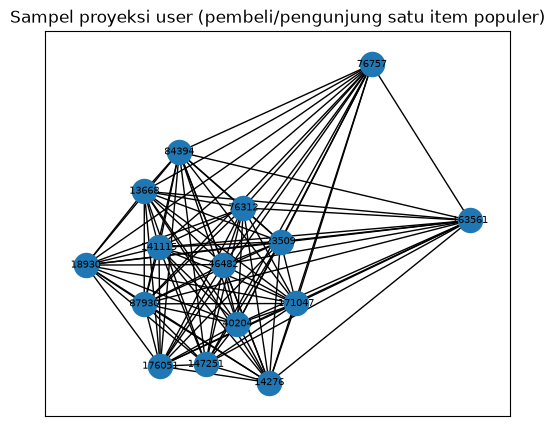

simpul: 15 | sisi: 105


In [10]:
# 2.1 no.4: VSM user (baris = user, kolom = item), nilai 1 jika ada interaksi
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN DISTINCT v.visitorId AS visitor, i.itemId AS item
"""
rec, _, _ = driver.execute_query(q, database_=DB)
pairs = pd.DataFrame([r.data() for r in rec])

user_ids = pairs["visitor"].astype("category")
item_ids = pairs["item"].astype("category")

X = csr_matrix(
    (np.ones(len(pairs)), (user_ids.cat.codes, item_ids.cat.codes)),
    shape=(user_ids.cat.categories.size, item_ids.cat.categories.size),
)

def karakter(M, nama):
    deg = np.diff(M.indptr)
    print(nama, "| shape:", M.shape, "| nnz:", M.nnz)
    print("density: %.6f" % (M.nnz / (M.shape[0] * M.shape[1])))
    print("nnz per baris -> rata-rata: %.2f, median: %d, maks: %d" % (deg.mean(), np.median(deg), deg.max()))

def plot_proyeksi(M, idx, label, judul):
    sub = normalize(M[idx])
    S_sub = (sub @ sub.T).toarray()
    G = nx.Graph()
    for a in range(len(idx)):
        G.add_node(label[a])
        for b in range(a + 1, len(idx)):
            if S_sub[a, b] > 0:
                G.add_edge(label[a], label[b], weight=S_sub[a, b])
    plt.figure(figsize=(6, 5))
    nx.draw_networkx(G, node_size=300, font_size=7)
    plt.title(judul)
    plt.show()
    print("simpul:", G.number_of_nodes(), "| sisi:", G.number_of_edges())

karakter(X, "VSM User (user x item)")

j_populer = int(np.argmax(np.asarray(X.sum(axis=0)).ravel()))
idx_user = X[:, j_populer].nonzero()[0][:15]
plot_proyeksi(X, idx_user, user_ids.cat.categories[idx_user].tolist(), "Sampel proyeksi user (pembeli/pengunjung satu item populer)")

**2.1 No. 4: VSM terhadap User.**

Setiap user direpresentasikan sebagai vektor biner sepanjang jumlah item, dengan nilai 1 jika user pernah melakukan view, addtocart, atau transaction pada item tersebut. Matriks yang terbentuk berukuran 42.752 x 44.556 dengan 115.327 entri dan density 0,000061, sehingga sangat jarang. Rata-rata satu user hanya berinteraksi dengan 2,70 item (median 2, maksimum 729), artinya sebagian besar user memiliki profil yang tipis. Plot networkx dibuat dari sampel 15 user dengan sisi untuk pasangan yang cosine similarity-nya lebih dari 0. Karena seluruh user pada sampel berbagi item yang sama, hasilnya graf lengkap (15 simpul dan 105 sisi), sehingga plot ini hanya menggambarkan sampel.

VSM Item (item x user) | shape: (44556, 42752) | nnz: 115327
density: 0.000061
nnz per baris -> rata-rata: 2.59, median: 1, maks: 144


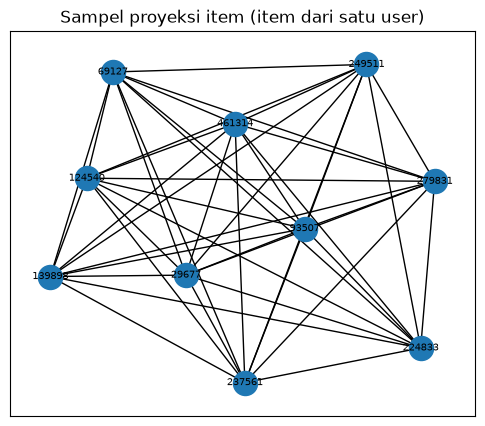

simpul: 10 | sisi: 45


In [11]:
# 2.1 no.5: VSM item (baris = item, kolom = user)
Xi = X.T.tocsr()
karakter(Xi, "VSM Item (item x user)")

deg_user = np.diff(X.indptr)
u0 = int(np.argsort(np.abs(deg_user - 10))[0])
idx_item = X[u0].indices
plot_proyeksi(Xi, idx_item, item_ids.cat.categories[idx_item].tolist(), "Sampel proyeksi item (item dari satu user)")

**2.1 No. 5: VSM terhadap Item.** 

Setiap item direpresentasikan sebagai vektor biner sepanjang jumlah user (transpose dari matriks sebelumnya), sehingga berukuran 44.556 x 42.752 dengan 115.327 entri dan density 0,000061. Rata-rata satu item hanya disentuh 2,59 user (median 1, maksimum 144), artinya setidaknya separuh item hanya dikunjungi satu user. Plot networkx dibuat dari 10 item milik satu user dan membentuk graf lengkap (10 simpul dan 45 sisi), sehingga hanya menggambarkan sampel.

In [12]:
# 2.1 no.6: perbandingan proyeksi
deg_user = np.asarray(X.sum(axis=1)).ravel()
deg_item = np.asarray(X.sum(axis=0)).ravel()

print("jumlah operasi proyeksi user-user:", int((deg_item ** 2).sum()))
print("jumlah operasi proyeksi item-item:", int((deg_user ** 2).sum()))
print("ukuran matriks similarity user:", X.shape[0] ** 2, "| item:", X.shape[1] ** 2)
print("rata-rata interaksi per user: %.2f | per item: %.2f" % (deg_user.mean(), deg_item.mean()))

jumlah operasi proyeksi user-user: 1045057
jumlah operasi proyeksi item-item: 2926253
ukuran matriks similarity user: 1827733504 | item: 1985237136
rata-rata interaksi per user: 2.70 | per item: 2.59


**2.1 No. 6: Perbandingan proyeksi.** 

Proyeksi antar user membutuhkan 1.045.057 operasi, sedangkan antar item membutuhkan 2.926.253 operasi. Matriks similarity user, yaitu 832.702 entri dibandingkan 2.695.924 pada percobaan awal proyeksi item. Dari sisi efektivitas, rata-rata interaksi per user (2,70) sedikit lebih tinggi daripada per item (2,59). Dengan demikian, proyeksi user dipilih untuk langkah berikutnya.

In [13]:
# 2.1 no.7: similarity cosine antar user (proyeksi user-user)
Xn = normalize(X)
S = (Xn @ Xn.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()
print(S.shape, S.nnz)

# record acuan: user dengan item terbanyak
ref_idx = int(np.argmax(deg_user))
ref_id = int(user_ids.cat.categories[ref_idx])

row = S.getrow(ref_idx).toarray().ravel()
top = np.argsort(-row)[:5]
hasil_py = [(int(user_ids.cat.categories[j]), float(row[j])) for j in top]
print("user acuan:", ref_id)
print(hasil_py)

(42752, 42752) 832702
user acuan: 286616
[(327437, 0.14442970747104034), (138131, 0.10937357936821143), (57905, 0.10682024943325152), (163561, 0.1059151188120963), (389532, 0.10284705155786099)]


**2.1 No. 7: Similarity** 

Matriks VSM user dinormalisasi, lalu cosine similarity dihitung sebagai Xn x Xn transpose dengan diagonal dinolkan. Hasilnya matriks 42.752 x 42.752 dengan 832.702 entri. Record acuan adalah user 286616 (user dengan item terbanyak, yaitu 729). Lima user paling mirip adalah 327437 (0,1444), 138131 (0,1094), 57905 (0,1068), 163561 (0,1059), dan 389532 (0,1028).

In [14]:
# 2.1 no.7a: Cypher 5 similarity tertinggi (cosine dari irisan item)
q_top5 = """
MATCH (a:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH a, collect(DISTINCT i) AS ia
UNWIND ia AS i
MATCH (b:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
WHERE b <> a
WITH a, size(ia) AS na, b, count(DISTINCT i) AS irisan
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(ib:Item)
WITH b, na, irisan, count(DISTINCT ib) AS nb
RETURN b.visitorId AS visitorId, irisan / sqrt(toFloat(na) * nb) AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
rec, _, _ = driver.execute_query(q_top5, ref=ref_id, database_=DB)
print(pd.DataFrame([r.data() for r in rec]))

   visitorId  similarity
0     327437    0.144430
1     138131    0.109374
2      57905    0.106820
3     163561    0.105915
4     389532    0.102847


**2.1 No. 7a: Cypher similarity tertinggi.** 

Query mengambil item user acuan, mencari user lain yang berinteraksi dengan item tersebut, lalu menghitung irisan item serta jumlah item masing-masing user (na dan nb). Similarity dihitung sebagai irisan / sqrt(na x nb), kemudian diurutkan menurun dan dibatasi dengan LIMIT 5.

In [15]:
# 2.1 no.7b: tulis similarity ke graf sebagai relasi SIMILAR_TO
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_=DB)

q_hitung = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n"
rec, _, _ = driver.execute_query(q_hitung, database_=DB)
n_sebelum = rec[0]["n"]

q_tulis = """
MATCH (a:Visitor {visitorId: $ref})
UNWIND $pasangan AS p
MATCH (b:Visitor {visitorId: p.visitorId})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = p.score
"""
pasangan = [{"visitorId": i, "score": s} for i, s in hasil_py]
driver.execute_query(q_tulis, ref=ref_id, pasangan=pasangan, database_=DB)

rec, _, _ = driver.execute_query(q_hitung, database_=DB)
n_sesudah = rec[0]["n"]
print("relasi SIMILAR_TO sebelum:", n_sebelum, "| sesudah:", n_sesudah)

q_cek = """
MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS dari, b.visitorId AS ke, s.score AS score
ORDER BY s.score DESC
"""
rec_sesudah, _, _ = driver.execute_query(q_cek, ref=ref_id, database_=DB)
print(pd.DataFrame([r.data() for r in rec_sesudah]))

relasi SIMILAR_TO sebelum: 0 | sesudah: 5
     dari      ke     score
0  286616  327437  0.144430
1  286616  138131  0.109374
2  286616   57905  0.106820
3  286616  163561  0.105915
4  286616  389532  0.102847


**2.1 No. 7b: Menuliskan similarity ke graf.** 

Kelima pasangan ditulis sebagai relasi SIMILAR_TO dengan properti score dari user acuan ke kelima user tersebut menggunakan UNWIND dan MERGE. Jumlah relasi SIMILAR_TO berubah dari 0 menjadi 5, dan query pembacaan menampilkan score 0,1444 sampai 0,1028.

[#F902]  _: <CONNECTION> error: Failed to read from defunct connection ResolvedIPv4Address(('34.126.171.25', 7687)) (ResolvedIPv4Address(('34.126.171.25', 7687))): ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)
Unable to retrieve routing information
Transaction failed and will be retried in 0.8725226740790696s (Unable to retrieve routing information)
[#C443]  _: <CONNECTION> error: Failed to read from defunct connection IPv4Address(('p-mt-3b814dd7cab7-15-0150.production-orch-0068.neo4j.io', 7687)) (ResolvedIPv4Address(('34.126.171.25', 7687))): ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)
Transaction failed and will be retried in 2.2765617471127344s (Failed to read from defunct connection IPv4Address(('p-mt-3b814dd7cab7-15-0150.production-orch-0068.neo4j.io', 7687)) (ResolvedIPv4Address(('34.126.171.25', 7687))))


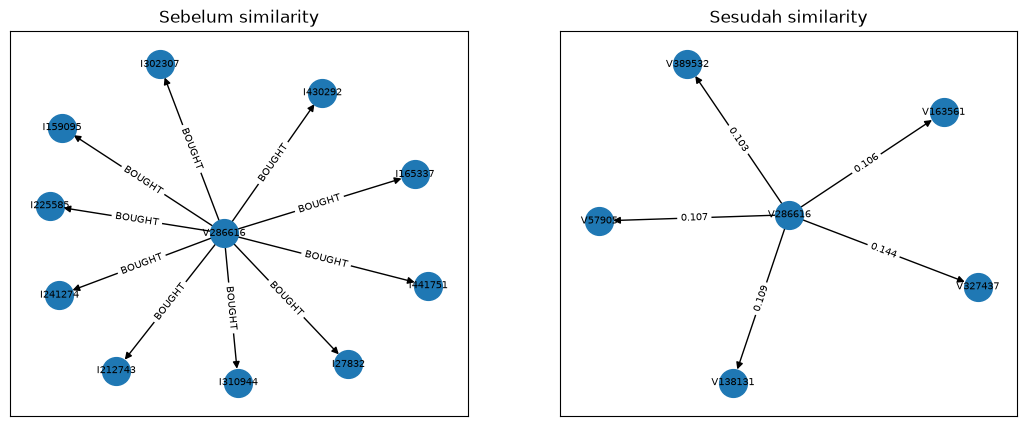

In [19]:
# 2.1 no.8: kondisi graf sebelum dan sesudah similarity
q_sebelum = """
MATCH (a:Visitor {visitorId: $ref})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN a.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
LIMIT 10
"""
rec_sebelum, _, _ = driver.execute_query(q_sebelum, ref=ref_id, database_=DB)

G1 = nx.DiGraph()
for r in rec_sebelum:
    G1.add_edge("V" + str(r["visitor"]), "I" + str(r["item"]), label=r["relasi"])

G2 = nx.DiGraph()
for r in rec_sesudah:
    G2.add_edge("V" + str(r["dari"]), "V" + str(r["ke"]), label=round(r["score"], 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for g, a, judul in [(G1, ax[0], "Sebelum similarity"), (G2, ax[1], "Sesudah similarity")]:
    pos = nx.spring_layout(g, seed=42)
    nx.draw_networkx(g, pos, ax=a, node_size=400, font_size=7)
    nx.draw_networkx_edge_labels(g, pos, edge_labels=nx.get_edge_attributes(g, "label"), ax=a, font_size=7)
    a.set_title(judul)
plt.show()

**2.1 No. 8: Graf sebelum dan sesudah similarity.** 

Sebelum perhitungan, query menampilkan relasi user acuan ke item (dibatasi 10, seluruhnya BOUGHT), sehingga hanya terdapat relasi Visitor ke Item. Sesudah perhitungan, muncul lima relasi SIMILAR_TO dari user 286616 ke user lain dengan score 0,103 sampai 0,144.

In [17]:
# 2.2 no.1: user acak (seed 42) lalu rekomendasi user-based KNN, k = 5
p2_baca = pd.read_csv("events_p2.csv")
riwayat = pairs.groupby("visitor")["item"].apply(set)
p2_item = p2_baca.groupby("visitorid")["itemid"].apply(set)

bersama = riwayat.index.intersection(p2_item.index)
kandidat = sorted(u for u in bersama if len(p2_item[u] - riwayat[u]) > 0)

rng = np.random.default_rng(42)
u = int(rng.choice(kandidat))
user_idx = user_ids.cat.categories.get_loc(u)
seen_idx = set(X[user_idx].indices)

k = 5
row = S.getrow(user_idx).toarray().ravel()
tetangga = [j for j in np.argsort(-row)[:k] if row[j] > 0]

skor = {}
for j in tetangga:
    for it in X[j].indices:
        if it not in seen_idx:
            skor[it] = skor.get(it, 0) + row[j]

urut = sorted(skor, key=lambda it: -skor[it])
rekom = [int(item_ids.cat.categories[it]) for it in urut[:5]]

print("user terpilih:", u, "| jumlah item di P1:", len(seen_idx))
print("tetangga (user):", [int(user_ids.cat.categories[j]) for j in tetangga])
print("top-5 rekomendasi:", rekom)
print("3 item yang diiklankan:", rekom[:3])

user terpilih: 121532 | jumlah item di P1: 7
tetangga (user): [699350, 232952, 219749, 805732, 163561]
top-5 rekomendasi: [20709, 46285, 165629, 196739, 218239]
3 item yang diiklankan: [20709, 46285, 165629]


**2.2 No. 1: Rekomendasi user-based KNN.** 

User dipilih dengan np.random.default_rng(seed=42) dari kandidat yang terurut. Terpilih user 121532 dengan 7 item di P1. Untuk k = 5, tetangga terdekatnya adalah 699350, 232952, 219749, 805732, dan 163561. Item tetangga yang belum dilihat user diberi skor berupa jumlah similarity, sehingga top-5 rekomendasinya adalah 20709, 46285, 165629, 196739, dan 218239. Tiga item yang diiklankan adalah 20709, 46285, dan 165629.

In [18]:
# 2.2 no.2: Hit@5 dan NDCG@5 (relevan = item baru yang disentuh user di P2)
relevan = p2_item[u] - riwayat[u]

hit = int(any(i in relevan for i in rekom[:5]))
dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rekom[:5]) if i in relevan)
idcg = sum(1 / np.log2(r + 2) for r in range(min(len(relevan), 5)))
ndcg = dcg / idcg

print("item relevan di P2:", len(relevan))
print("Hit@5:", hit)
print("NDCG@5: %.4f" % ndcg)

item relevan di P2: 1
Hit@5: 0
NDCG@5: 0.0000


**2.2 No. 2: Hit@5 dan NDCG@5.** 

Item relevan adalah item baru (belum ada di P1) yang diakses user pada P2, dan user 121532 hanya memiliki satu item tersebut. Hit@5 bernilai 1 jika terdapat item relevan di top-5, sedangkan NDCG@5 adalah DCG dibagi IDCG. Hasilnya Hit@5 = 0 dan NDCG@5 = 0,0000 karena tidak ada item relevan di top-5.